<a href="https://colab.research.google.com/github/ajaypandey2402/ICL-ML-Specialization/blob/main/lab_PageRank.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Part 1: 6 and 7 websites examples**

In [ ]:
# Before we begin, let's load the libraries.
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

%matplotlib inline
np.set_printoptions(suppress=True)

In [ ]:
# Replace the ??? here with the probability of clicking a link to each website when leaving Website F (FaceSpace).
L = np.array([[0,   1/2, 1/3, 0, 0,   0],
              [1/3, 0,   0,   0, 1/2, 0],
              [1/3, 1/2, 0,   1, 0,   1/2],
              [1/3, 0,   1/3, 0, 1/2, 1/2],
              [0,   0,   0,   0, 0,   0],
              [0,   0,   1/3, 0, 0,   0]])

In [ ]:
eVals, eVecs = la.eig(L) # Gets the eigenvalues and vectors
order = np.absolute(eVals).argsort()[::-1] # Orders them by their eigenvalues
eVals = eVals[order]
eVecs = eVecs[:,order]

r = eVecs[:, 0] # Sets r to be the principal eigenvector
100 * np.real(r / np.sum(r)) # Make this eigenvector sum to one, then multiply by 100 Procrastinating Pats

array([16.        ,  5.33333333, 40.        , 25.33333333,  0.        ,
       13.33333333])

In [ ]:
r = 100 * np.ones(6) / 6 # Sets up this vector (6 entries of 1/6 × 100 each)
r # Shows it's value

array([16.66666667, 16.66666667, 16.66666667, 16.66666667, 16.66666667,
       16.66666667])

In [ ]:
r = L @ r # Apply matrix L to r
r # Show it's value
# Re-run this cell multiple times to converge to the correct answer.

array([13.88888889, 13.88888889, 38.88888889, 27.77777778,  0.        ,
        5.55555556])

In [ ]:
r = 100 * np.ones(6) / 6 # Sets up this vector (6 entries of 1/6 × 100 each)
for i in np.arange(100) : # Repeat 100 times
    r = L @ r
r

array([16.        ,  5.33333333, 40.        , 25.33333333,  0.        ,
       13.33333333])

In [ ]:
r = 100 * np.ones(6) / 6 # Sets up this vector (6 entries of 1/6 × 100 each)
lastR = r
r = L @ r
i = 0
while la.norm(lastR - r) > 0.01 :
    lastR = r
    r = L @ r
    i += 1
print(str(i) + " iterations to convergence.")
r

18 iterations to convergence.


array([16.00149917,  5.33252025, 39.99916911, 25.3324738 ,  0.        ,
       13.33433767])

In [ ]:
# We'll call this one L2, to distinguish it from the previous L.
L2 = np.array([[0,   1/2, 1/3, 0, 0,   0, 0 ],
               [1/3, 0,   0,   0, 1/2, 0, 0 ],
               [1/3, 1/2, 0,   1, 0,   1/3, 0 ],
               [1/3, 0,   1/3, 0, 1/2, 1/3, 0 ],
               [0,   0,   0,   0, 0,   0, 0 ],
               [0,   0,   1/3, 0, 0,   0, 0 ],
               [0,   0,   0,   0, 0,   1/3, 1 ]])

In [ ]:
r = 100 * np.ones(7) / 7 # Sets up this vector (6 entries of 1/6 × 100 each)
lastR = r
r = L2 @ r
i = 0
while la.norm(lastR - r) > 0.01 :
    lastR = r
    r = L2 @ r
    i += 1
print(str(i) + " iterations to convergence.")
r

131 iterations to convergence.


array([ 0.03046998,  0.01064323,  0.07126612,  0.04423198,  0.        ,
        0.02489342, 99.81849527])

In [ ]:
d = 0.5 # Feel free to play with this parameter after running the code once.
M = d * L2 + (1-d)/7 * np.ones([7, 7]) # np.ones() is the J matrix, with ones for each entry.

In [ ]:
r = 100 * np.ones(7) / 7 # Sets up this vector (6 entries of 1/6 × 100 each)
lastR = r
r = M @ r
i = 0
while la.norm(lastR - r) > 0.01 :
    lastR = r
    r = M @ r
    i += 1
print(str(i) + " iterations to convergence.")
r

8 iterations to convergence.


array([13.68217054, 11.20902965, 22.41964343, 16.7593433 ,  7.14285714,
       10.87976354, 17.90719239])

**Part 2: PageRank for an arbitrarily large probability matrix**

In [ ]:
# GRADED FUNCTION
# Complete this function to provide the PageRank for an arbitrarily sized internet.
# I.e. the principal eigenvector of the damped system, using the power iteration method.
# (Normalisation doesn't matter here)
# The functions inputs are the linkMatrix, and d the damping parameter - as defined in this worksheet.
# (The damping parameter, d, will be set by the function - no need to set this yourself.)
def pageRank(linkMatrix, d) :
    n = linkMatrix.shape[0]

    # Create matrix M with coefficient d
    # J-matrix is a matrix of ones, sized [n, m]
    M = d * linkMatrix + (1 - d) / n * np.ones([n, n])

    # Initial vector
    r = 100 * np.ones(n) / n

    # Launch Power Iteration until stable
    lastR = r
    r = M @ r
    while la.norm(lastR - r) > 0.01:
        lastR = r
        r = M @ r
    return r

In [ ]:
import numpy as np

# Function of generation matrix of connections of arbitrarily size (course analog)
def generate_internet(size):
    np.random.seed(42) # Stability for tests
    # Random probability matrix
    matrix = np.random.rand(size, size)
    # Normalise colimns so that sum equals 1
    matrix = matrix / matrix.sum(axis=0)
    return matrix

In [ ]:
# Use the following function to generate internets of different sizes.
generate_internet(5)

array([[0.27818378, 0.39246082, 0.22540133, 0.27083479, 0.08700497],
       [0.11586248, 0.02397728, 0.26671977, 0.27194613, 0.394862  ],
       [0.01528881, 0.40038486, 0.25633229, 0.09606281, 0.10139606],
       [0.13622082, 0.1255931 , 0.16158713, 0.19541314, 0.16240612],
       [0.45444412, 0.05758394, 0.08995948, 0.16574313, 0.25433086]])

In [ ]:
# Test your PageRank method against the built in "eig" method.
# You should see yours is a lot faster for large internets
L = generate_internet(10)

In [ ]:
pageRank(L, 1)

array([10.87476123,  8.11293318,  8.7487492 , 11.12622023,  8.71128495,
       11.39396   ,  9.88796593, 10.10544503, 12.00284969,  9.03583054])

In [ ]:
# Do note, this is calculating the eigenvalues of the link matrix, L,
# without any damping. It may give different results that your pageRank function.
# If you wish, you could modify this cell to include damping.
# (There is no credit for this though)
eVals, eVecs = la.eig(L) # Gets the eigenvalues and vectors
order = np.absolute(eVals).argsort()[::-1] # Orders them by their eigenvalues
eVals = eVals[order]
eVecs = eVecs[:,order]

r = eVecs[:, 0]
100 * np.real(r / np.sum(r))

array([10.87474915,  8.11298297,  8.74878036, 11.12616346,  8.7115165 ,
       11.3932999 ,  9.88817462, 10.10541935, 12.0029115 ,  9.0360022 ])

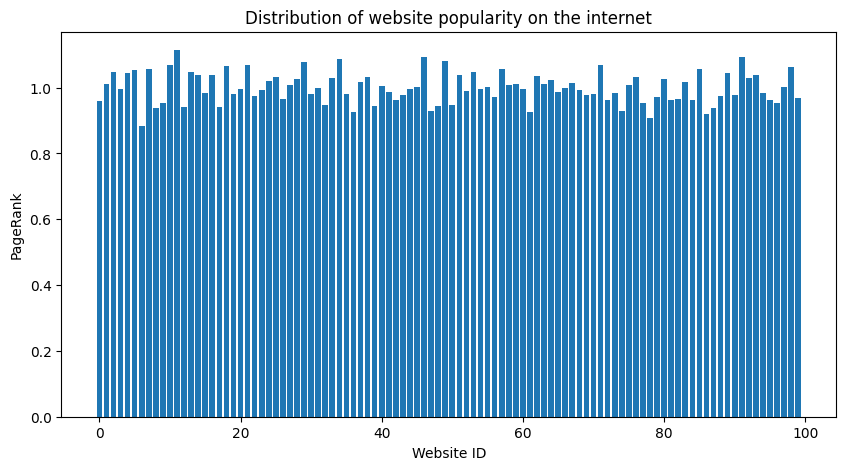

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

# Generate internet for 100 websites and calculate PageRank
r = pageRank(generate_internet(100), 0.9)

# Build a diagram
plt.figure(figsize=(10, 5))
plt.bar(np.arange(r.shape[0]), r)
plt.xlabel("Website ID")
plt.ylabel("PageRank")
plt.title("Distribution of website popularity on the internet")
plt.show()